In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp -r /content/drive/MyDrive/BLENDER/dataset/dataset_v37_cleared.zip -d /content/
!unzip /content/dataset_v37_cleared.zip -d /content/dataset/

Archive:  /content/dataset_v37_cleared.zip
   creating: /content/dataset/train/
  inflating: /content/dataset/train/0a_model_TUWIEN_patch_0001.laz  
  inflating: /content/dataset/train/0a_model_TUWIEN_patch_0002.laz  
  inflating: /content/dataset/train/0b_model_TUWIEN_patch_0001.laz  
  inflating: /content/dataset/train/0b_model_TUWIEN_patch_0002.laz  
  inflating: /content/dataset/train/0_modela_CULS_patch_0001.laz  
  inflating: /content/dataset/train/0_modela_CULS_patch_0002.laz  
  inflating: /content/dataset/train/0_modelb_CULS_patch_0001.laz  
  inflating: /content/dataset/train/0_modelb_CULS_patch_0002.laz  
  inflating: /content/dataset/train/0_model_10_20251117_patch_0001.laz  
  inflating: /content/dataset/train/0_model_10_20251117_patch_0002.laz  
  inflating: /content/dataset/train/0_model_11_20251117_patch_0001.laz  
  inflating: /content/dataset/train/0_model_11_20251117_patch_0002.laz  
  inflating: /content/dataset/train/0_model_12_20251117_patch_0001.laz  
  inflating

In [ ]:
!pip uninstall torch torchvision torchaudio -y
!pip install torch==2.5.1+cu124 torchvision==0.20.1+cu124 torchaudio==2.5.1+cu124 --index-url https://download.pytorch.org/whl/cu124

Found existing installation: torch 2.11.0+cu128
Uninstalling torch-2.11.0+cu128:
  Successfully uninstalled torch-2.11.0+cu128
Found existing installation: torchvision 0.26.0+cu128
Uninstalling torchvision-0.26.0+cu128:
  Successfully uninstalled torchvision-0.26.0+cu128
Found existing installation: torchaudio 2.11.0+cu128
Uninstalling torchaudio-2.11.0+cu128:
  Successfully uninstalled torchaudio-2.11.0+cu128
Looking in indexes: https://download.pytorch.org/whl/cu124
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 908.2/908.2 MB 516.2 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 124.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 117.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 86.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 60.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 120.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
import os
import torch
os.environ['TORCH'] = torch.__version__
print(torch.__version__)

!pip install -q torch-scatter -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q torch-sparse -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q torch-cluster -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q git+https://github.com/pyg-team/pytorch_geometric.git

!pip install torchmetrics
!pip install laspy[lazrs]

!pip install wandb

2.5.1+cu124
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 67.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 30.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 3.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 649.3/649.3 kB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.1/86.1 kB 11.2 MB/s eta 0:00:00


In [ ]:
# ==========================================================
# 1. STANDARD LIBRARY & SYSTEM
# ==========================================================
import os
import math
import random
import shutil
import datetime
from glob import glob
from collections import Counter

# ==========================================================
# 2. DATA PROCESSING & UTILS
# ==========================================================
import numpy as np
import laspy
from tqdm.notebook import tqdm
from PIL import Image

# ==========================================================
# 3. PYTORCH CORE
# ==========================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from torch import Tensor
from torch.nn import Sequential as Seq, Linear, ReLU, BatchNorm1d as BN

# ==========================================================
# 4. PYTORCH GEOMETRIC (PyG)
# ==========================================================
from torch_geometric.data import Data, InMemoryDataset
from torch_geometric.loader import DataLoader
import torch_geometric.transforms as T
from torch_geometric.transforms import BaseTransform
from torch_scatter import scatter, scatter_mean

# ==========================================================
# 5. METRICS & EVALUATION
# ==========================================================
import torchmetrics
from torchmetrics import MetricCollection
from torchmetrics.classification import (
    MulticlassJaccardIndex,
    MulticlassF1Score,
    MulticlassPrecision,
    MulticlassRecall
)
from sklearn.metrics import classification_report, confusion_matrix

# ==========================================================
# 6. LOGGING & VISUALIZATION
# ==========================================================
import wandb
from torch.utils.tensorboard import SummaryWriter
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import to_rgb
from mpl_toolkits.mplot3d import Axes3D

from torch.optim.lr_scheduler import LinearLR, SequentialLR
import torch.optim.lr_scheduler as lr_scheduler

# Main Configuration

In [ ]:
# PATHS ---------------------------------------------------------------------------------------------
DATASET_DIR = "/content/dataset"
OUTPUT_DIR = "/content/output"
EXP_NAME = "PointNext_Forest_V1"

# DATASET OPTIONS
SEMANTIC_LABEL_ATTRIBUTE = "classification_mapped"

TARGET_DENSITY = 50.0 # points/m2
MAX_POINTS = 25000
PATCH_SIZE_M = 20

CLASS_NAMES = {
    'background':0,
    'trunk':1,
    'tree_crown':2,
}

# ARCHITECTURE
MODEL_CONFIG = {
    "name": "PointNetPP",
    "params": {
        "in_channels": 3, #xyz
        "feat_dim": 32,
        "num_classes": len(CLASS_NAMES)}}

MODEL_CONFIG = {
    "name": "PointNext",
    "params": {
        "in_channels": 3,
        "feat_dim": 32,
        "num_classes": len(CLASS_NAMES),
        "initial_radius": 0.1, # Adjusted for forest scale
        "k_neighbors": 32
    }
}


# HYPERPARAMETERS
BATCH_SIZE = 8
NUM_EPOCHS = 20
WARMUP_EPOCHS = 5
RESUME = False
PATH_TO_CKPT = None
PRIMARY_METRIC = "val/mIoU"  # Which metric decides the 'best' model


# LOSS FUNCTION SETTINGS --------------------------------------------------------------------------------
#CRITERION_CONFIG = {
#    "name": "CrossEntropyLoss",
#    "params": {
#        "label_smoothing": 0.1,
#    }
#}

CRITERION_CONFIG = {
    "name": "DiceFocalLoss",
    "params": {
        "gamma": 2.0,           # Higher = focus more on hard points (stems)
        "dice_weight": 0.5,     # Balance between Dice (shape) and Focal (points)
        "label_smoothing": 0.1  # Helps prevents over-confidence
    }
}

# OPTIMIZER CONFIGURATION ---------------------------------------------------------------------------
OPTIMIZER_CONFIG = {
    "name": "AdamW",  # Options: "Adam", "AdamW", "SGD", "RMSprop"
    "params": {
        "lr": 1e-4,
        "weight_decay": 1e-4,
        # "amsgrad": True
    }
}


# SCHEDULER CONFIGURATION ---------------------------------------------------------------------------
SCHEDULER_CONFIG = {
    "name": "CosineAnnealingLR",
    "params": {
        "T_max": NUM_EPOCHS - WARMUP_EPOCHS, # Important: Decay happens over remaining epochs
        "eta_min": 1e-6
    }
}

# Tip: If you want to use StepLR, change to:
# "name": "StepLR", "params": {"step_size": 20, "gamma": 0.1}


# LOGGER
LOGGER = "wandb"  # tensorboard/wandb
# wywal to!
LS_API_KEY ="######"


# METRICS CONFIGURATION -----------------------------------------------------------------------------
METRICS_CONFIG = {
    "iou": {"name": "MulticlassJaccardIndex", "params": {"average": None}},
    "f1":  {"name": "MulticlassF1Score", "params": {"average": "macro"}}
}

# VISUALISATION
VIS_FREQ = 1
NUM_VIS = 3
SEMANTIC_COLOR_MAP = {
    0: 'gray',
    1: 'saddlebrown',
    2: 'forestgreen',
}

SEED = 42

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [ ]:
def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 42
set_seed(SEED)

# Engine

## Dataset

In [ ]:
class ForestLAZSemanticDataset(InMemoryDataset):
    def __init__(
        self,
        root_dir,
        split="train",
        transform=None,
        pre_transform=None,
        pre_filter=None,
    ):
        assert split in ["train", "val", "test"]
        self.split = split

        super().__init__(os.path.join(root_dir, split), transform, pre_transform, pre_filter)

        self.data, self.slices = torch.load(self.processed_paths[0], weights_only=False)

    @property
    def raw_dir(self):
        return self.root

    @property
    def processed_dir(self):
        return os.path.join(self.root, "processed")

    @property
    def raw_file_names(self):
        all_files = glob(os.path.join(self.raw_dir, "*.laz")) + glob(os.path.join(self.raw_dir, "*.las"))
        return sorted([os.path.basename(p) for p in all_files])

    @property
    def processed_file_names(self):
        return "data.pt"

    def process(self):
        data_list = []
        if not self.raw_file_names:
            raise FileNotFoundError(f"No .laz/.las files in {self.raw_dir}")

        print(f"--- Start processing: {len(self.raw_file_names)} files ({self.split}) ---")

        for raw_path_str in self.raw_paths:
            try:
                las = laspy.read(raw_path_str)
                positions = np.vstack((las.x, las.y, las.z)).T

                # shift to zero
                positions -= positions.min(axis=0)

                labels = np.array(las[SEMANTIC_LABEL_ATTRIBUTE])

                data = Data(
                    pos=torch.from_numpy(positions).to(torch.float),
                    y=torch.from_numpy(labels).to(torch.long)
                )

                if self.pre_transform is not None:
                    data = self.pre_transform(data)

                data_list.append(data)

            except Exception as e:
                print(f"Error in file {raw_path_str}: {e}")

        if not data_list:
            print("Warning: No processed files.")
            return

        # Collate
        data, slices = self.collate(data_list)
        os.makedirs(self.processed_dir, exist_ok=True)
        torch.save((data, slices), self.processed_paths[0])
        print(f"--- Finished! File saved as: {self.processed_paths[0]} ---")

    @property
    def num_classes(self):
        return len(CLASS_NAMES)

## Transformations

In [ ]:
class NormalizePositions(BaseTransform):
    def __init__(self, patch_size=20.0):
        super().__init__()
        self.patch_size = patch_size
        self.fixed_scale = patch_size / 2

    def forward(self, data: Data) -> Data:
        pos = data.pos.clone()

        min_z = pos[:, 2].min()
        pos[:, 2] -= min_z

        center_xy = pos[:, :2].mean(dim=0)
        pos[:, :2] -= center_xy

        pos /= self.fixed_scale

        data.pos = pos
        # only raw geometry as data features
        data.x = pos.clone()

        return data

In [ ]:
class AreaBasedSampler(BaseTransform):
    """
    """
    def __init__(
        self,
        target_density: float = 50.0, # ile punktów na m2
        area_grid_res: float = 0.5,   # rozdzielczość siatki do liczenia pola
        max_points: int = 50000,
        min_points: int = 1024
    ):
        super().__init__()
        self.target_density = target_density
        self.area_grid_res = area_grid_res
        self.max_points = max_points
        self.min_points = min_points

    def _estimate_area(self, pos):
        xy = pos[:, :2]
        xy_min = xy.min(dim=0)[0]


        grid_coords = torch.floor((xy - xy_min) / self.area_grid_res).to(torch.long)
        grid_ids = grid_coords[:, 0] + grid_coords[:, 1] * (grid_coords[:, 0].max() + 1)
        num_occupied_cells = torch.unique(grid_ids).size(0)

        actual_area = num_occupied_cells * (self.area_grid_res ** 2)
        return max(actual_area, 1e-4)

    def forward(self, data: Data) -> Data:
        pos = data.pos
        num_nodes = pos.size(0)

        area = self._estimate_area(pos)
        target_num = int(area * self.target_density)
        target_num = max(min(target_num, self.max_points), self.min_points)

        if num_nodes >= target_num:
            # Downsampling:
            choice = torch.randperm(num_nodes, device=pos.device)[:target_num]
        else:
            # Upsampling
            extra_idx = torch.randint(0, num_nodes, (target_num - num_nodes,), device=pos.device)
            choice = torch.cat([torch.arange(num_nodes, device=pos.device), extra_idx])

        for key, item in data:
            if torch.is_tensor(item) and item.size(0) == num_nodes:
                data[key] = item[choice]

        return data

In [ ]:
class OneOf(BaseTransform):
    """Randomly selects and applies exactly one transform from the provided list."""
    def __init__(self, transforms, p=None):
        super().__init__()
        self.transforms = transforms
        self.p = p if p is not None else [1.0 / len(transforms)] * len(transforms)

    def forward(self, data: Data) -> Data:
        t = random.choices(self.transforms, weights=self.p, k=1)[0]
        return t(data)

class ClassLocalDensityChange(BaseTransform):
    """Randomly reduces point density within a spherical region for a specific class."""
    def __init__(self, target_class_id: int, radius: float = 2.0, factor: float = 0.2, p: float = 0.5):
        super().__init__()
        self.target_class_id = target_class_id
        self.radius = radius
        self.factor = factor
        self.p = p

    def forward(self, data: Data) -> Data:
        if torch.rand(1) > self.p or not hasattr(data, 'y'): return data
        pos, labels = data.pos, data.y
        indices = (labels == self.target_class_id).nonzero().squeeze()
        if indices.numel() == 0: return data

        center = pos[indices[torch.randint(0, indices.numel(), (1,))]]
        dist = torch.norm(pos - center, dim=1)
        target_sphere_mask = (dist <= self.radius) & (labels == self.target_class_id)
        other_mask = ~target_sphere_mask

        target_idx = target_sphere_mask.nonzero().squeeze()
        if target_idx.numel() > 0:
            keep_num = int(target_idx.numel() * self.factor)
            keep_idx = target_idx[torch.randperm(target_idx.numel())[:keep_num]]
            final_mask = torch.zeros(pos.size(0), dtype=torch.bool, device=pos.device)
            final_mask[other_mask] = True
            final_mask[keep_idx] = True

            for key, item in data:
                if torch.is_tensor(item) and item.size(0) == pos.size(0):
                    data[key] = item[final_mask]
        return data

class RandomSlope(BaseTransform):
    """Simulates sloped terrain by tilting the Z-coordinates relative to XY plane."""
    def __init__(self, max_angle_deg=15, p=0.5):
        super().__init__()
        self.max_angle_deg = max_angle_deg
        self.p = p

    def forward(self, data: Data) -> Data:
        if random.random() > self.p: return data
        pos = data.pos
        max_slope = math.tan(math.radians(self.max_angle_deg))
        slope_x, slope_y = [random.uniform(-max_slope, max_slope) for _ in range(2)]
        x_c, y_c = (pos[:, 0].max() + pos[:, 0].min())/2, (pos[:, 1].max() + pos[:, 1].min())/2
        data.pos[:, 2] += slope_x * (pos[:, 0] - x_c) + slope_y * (pos[:, 1] - y_c)
        return data

class RandomElasticDistortion(BaseTransform):
    """Applies non-linear spatial warping using smoothed 3D noise."""
    def __init__(self, granularity=(0.2, 0.2, 0.2), magnitude=(0.1, 0.1, 0.1)):
        super().__init__()
        self.granularity, self.magnitude = torch.tensor(granularity), torch.tensor(magnitude)

    def forward(self, data: Data) -> Data:
        if data.pos is None: return data
        device = data.pos.device
        noise = (torch.rand(1, 3, 5, 5, 5, device=device) - 0.5) * 2
        noise = torch.nn.functional.conv_transpose3d(noise, torch.ones((1,1,3,3,3), device=device).repeat(3,1,1,1,1)/27.0, stride=2, groups=3).permute(0,2,3,4,1).squeeze(0)
        p_min, p_max = data.pos.min(0)[0], data.pos.max(0)[0]
        p_norm = (data.pos - p_min) / (p_max - p_min + 1e-8)
        idx = (p_norm * torch.tensor(noise.shape[:3], device=device) - 0.5).long().clamp(min=0)
        dist = noise[idx[:,0].clamp(max=noise.shape[0]-1), idx[:,1].clamp(max=noise.shape[1]-1), idx[:,2].clamp(max=noise.shape[2]-1)]
        data.pos += dist * (p_max - p_min) * self.magnitude.to(device)
        return data

class ForestGeometryThickener(BaseTransform):
    """Upsamples specific classes by duplicating points with random jitter."""
    def __init__(self, upsample_factor: float = 2.0, jitter_std: float = 0.01, target_class_ids: list = [1], p: float = 0.5):
        super().__init__()
        self.upsample_factor, self.jitter_std, self.target_class_ids, self.p = upsample_factor, jitter_std, target_class_ids, p

    def forward(self, data: Data) -> Data:
        if torch.rand(1) > self.p or not hasattr(data, 'y'): return data
        mask = torch.zeros(data.pos.size(0), dtype=torch.bool, device=data.pos.device)
        for cid in self.target_class_ids: mask |= (data.y == cid)
        indices = torch.nonzero(mask).squeeze()
        if indices.numel() == 0: return data
        num_add = int(indices.numel() * (self.upsample_factor - 1.0))
        if num_add <= 0: return data
        chosen = indices[torch.randint(0, indices.numel(), (num_add,))]
        new_pos = data.pos[chosen] + torch.randn((num_add, 3), device=data.pos.device) * self.jitter_std
        old_num = data.pos.size(0)
        data.pos = torch.cat([data.pos, new_pos], dim=0)
        for key in list(data.keys()):
            if key == 'pos': continue
            item = getattr(data, key)
            if torch.is_tensor(item) and item.size(0) == old_num:
                setattr(data, key, torch.cat([item, item[chosen]], dim=0))
        return data

## Class Weights

In [ ]:
def calculate_class_weights(dataset):
    """
    Computes inverse frequency weights to balance the loss function.
    """
    print("Calculating class weights from dataset...")
    # Get all labels from the dataset
    all_labels = dataset.data.y.numpy()
    counts = Counter(all_labels)

    total_points = len(all_labels)
    num_classes = len(CLASS_NAMES)

    # Calculate weights: W = Total / (Num_Classes * Count_of_Class)
    weights = []
    for i in range(num_classes):
        count = counts.get(i, 0)
        if count > 0:
            weight = total_points / (num_classes * count)
        else:
            weight = 1.0 # fallback for missing classes
        weights.append(weight)

    return torch.tensor(weights, dtype=torch.float).to(device)

## Architecture

### Custom FPS & KNN

In [ ]:
def custom_fps(pos, batch, ratio):
    """Pure PyTorch Farthest Point Sampling (Batch-aware)."""
    indices = []
    for b in torch.unique(batch):
        mask = (batch == b)
        cloud_pos = pos[mask]
        cloud_indices = torch.where(mask)[0]
        num_points = cloud_pos.size(0)
        num_samples = max(1, int(num_points * ratio))
        selected_idx = torch.zeros(num_samples, dtype=torch.long, device=pos.device)
        distances = torch.ones(num_points, device=pos.device) * 1e10
        farthest = 0
        for i in range(num_samples):
            selected_idx[i] = farthest
            centroid = cloud_pos[farthest].view(1, 3)
            dist = torch.sum((cloud_pos - centroid) ** 2, dim=-1)
            distances = torch.min(distances, dist)
            farthest = torch.argmax(distances)
        indices.append(cloud_indices[selected_idx])
    return torch.cat(indices)

def custom_knn(x, y, k, batch_x, batch_y):
    """Pure PyTorch k-Nearest Neighbors (Batch-aware)."""
    row_list, col_list = [], []
    for b in torch.unique(batch_x):
        mask_x, mask_y = (batch_x == b), (batch_y == b)
        x_b, y_b = x[mask_x], y[mask_y]
        idx_x, idx_y = torch.where(mask_x)[0], torch.where(mask_y)[0]

        # Compute distance matrix [num_y, num_x]
        dist = torch.cdist(y_b, x_b)

        # Get k nearest neighbors
        _, k_indices = torch.topk(dist, k=k, dim=-1, largest=False)

        # row: indices in y (sampled points), col: indices in x (all points)
        row = torch.arange(y_b.size(0), device=x.device).view(-1, 1).repeat(1, k).view(-1)
        col = k_indices.view(-1)

        row_list.append(idx_y[row])
        col_list.append(idx_x[col])

    return torch.stack([torch.cat(row_list), torch.cat(col_list)], dim=0)

def custom_knn_interpolate(x, pos_coarse, pos_fine, batch_coarse, batch_fine, k=3):
    """Pure PyTorch Inverse Distance Weighting interpolation."""
    # Find 3 nearest neighbors in coarse cloud for each point in fine cloud
    edge_index = custom_knn(pos_coarse, pos_fine, k, batch_coarse, batch_fine)
    row, col = edge_index

    # Calculate distances
    dist = torch.sum((pos_fine[row] - pos_coarse[col])**2, dim=-1).sqrt()
    dist = torch.clamp(dist, min=1e-10)
    weight = 1.0 / dist

    # Weighted average of features
    # row: destination index, col: source index, x[col]: source features
    from torch_scatter import scatter
    weighted_features = x[col] * weight.view(-1, 1)
    sum_weights = scatter(weight, row, dim=0, dim_size=pos_fine.size(0), reduce='sum').view(-1, 1)
    out = scatter(weighted_features, row, dim=0, dim_size=pos_fine.size(0), reduce='sum')

    return out / sum_weights

### Semantic head

In [ ]:
class SemanticHead(nn.Module):
    """
    Point-wise Semantic Classification Head.
    Maps high-dimensional latent features to raw semantic scores (logits).
    """
    def __init__(
        self,
        in_dim: int = 128,
        num_classes: int = 3
    ) -> None:
        super().__init__()

        # Multi-layer perceptron for per-point classification
        self.mlp = nn.Sequential(
            Linear(in_dim, 128),
            BN(128),
            ReLU(inplace=True),
            nn.Dropout(0.1),  # Added for better generalization
            Linear(128, num_classes)
        )

    def forward(self, features: Tensor) -> Tensor:
        """
        Input: [N_points, in_dim] - High-level features from the backbone.
        Output: [N_points, num_classes] - Raw logits for CrossEntropyLoss.
        """
        return self.mlp(features)

### Pointnet++ Based Model

#### Backbone

In [ ]:
def MLP(channels, batch_norm=True, last_act=True):
    """
    Constructs an MLP sequence.
    Technical flags have defaults to keep the backbone code clean.
    """
    layers = []
    for i in range(1, len(channels)):
        layers.append(Linear(channels[i - 1], channels[i]))
        if batch_norm:
            layers.append(BN(channels[i]))
        if (i < len(channels) - 1) or last_act:
            layers.append(ReLU(inplace=True))
    return Seq(*layers)

class SharedMLP(nn.Module):
    """
    Point-wise MLP. Default flags are set for common use cases.
    """
    def __init__(self, channels, batch_norm=True, dropout=0.0, last_act=True):
        super().__init__()
        self.mlp = MLP(channels, batch_norm, last_act)
        self.drop = nn.Dropout(dropout) if dropout > 0 else None

    def forward(self, x):
        x = self.mlp(x)
        if self.drop is not None:
            x = self.drop(x)
        return x

In [ ]:
class SAModule(nn.Module):
    def __init__(self, ratio, k, nn_module):
        super().__init__()
        self.ratio = ratio
        self.k = k
        self.conv = nn_module

    def forward(self, x, pos, batch):
        # Using custom implementations
        idx = custom_fps(pos, batch, ratio=self.ratio)
        edge_index = custom_knn(pos, pos[idx], self.k, batch, batch[idx])
        row, col = edge_index

        x_group = scatter(x[col], row, dim=0, dim_size=idx.size(0), reduce='max')
        x_out = self.conv(x_group)
        return x_out, pos[idx], batch[idx]

class FPModule(nn.Module):
    def __init__(self, k, in_channels, mlp_channels):
        super().__init__()
        self.k = k
        self.mlp = SharedMLP([in_channels] + mlp_channels)

    def forward(self, x_coarse, pos_coarse, batch_coarse, x_skip, pos_skip, batch_skip):
        # Using custom interpolation
        x_interp = custom_knn_interpolate(
            x_coarse, pos_coarse, pos_skip,
            batch_coarse, batch_skip, k=self.k
        )

        # Skip connection & MLP
        x_out = torch.cat([x_interp, x_skip], dim=1) if x_skip is not None else x_interp
        return self.mlp(x_out), pos_skip, batch_skip

In [ ]:
class PointNet2Backbone(nn.Module):
    def __init__(self, in_channels, feat_dim):
        super().__init__()

        self.sa1 = SAModule(0.5, 32, SharedMLP([in_channels, 64, 128]))
        self.sa2 = SAModule(0.25, 48, SharedMLP([128, 256, 256]))
        self.sa3 = SAModule(0.1, 64, SharedMLP([256, 512, 512]))

        self.fp3 = FPModule(3, 512 + 256, [512, 256])
        self.fp2 = FPModule(3, 256 + 128, [256, 128])
        self.fp1 = FPModule(3, 128 + in_channels, [256, feat_dim])

    def forward(self, x, pos, batch):
        l1_x, l1_pos, l1_batch = self.sa1(x, pos, batch)
        l2_x, l2_pos, l2_batch = self.sa2(l1_x, l1_pos, l1_batch)
        l3_x, l3_pos, l3_batch = self.sa3(l2_x, l2_pos, l2_batch)

        l2_x_up, _, _ = self.fp3(l3_x, l3_pos, l3_batch, l2_x, l2_pos, l2_batch)
        l1_x_up, _, _ = self.fp2(l2_x_up, l2_pos, l2_batch, l1_x, l1_pos, l1_batch)
        l0_x_up, _, _ = self.fp1(l1_x_up, l1_pos, l1_batch, x, pos, batch)

        return l0_x_up

#### Model

In [ ]:
class PointNetPPModel(nn.Module):
    """
    Full Semantic Segmentation Model (Encoder).
    Combines PointNet2 Backbone with the Semantic Classification Head.
    """
    def __init__(self, in_channels, feat_dim, num_classes):
        super().__init__()

        # Initialize internal backbone
        self.backbone = PointNet2Backbone(in_channels, feat_dim)

        # Initialize internal semantic head (using your existing SemanticHead class)
        self.sem_head = SemanticHead(feat_dim, num_classes)

    def forward(self, data):
        # Extract basic data from PyG object
        pos, x, batch = data.pos, data.x, data.batch

        # Fallback to positions as features if x is not present
        if x is None:
            x = pos

        # 1. Feature Extraction via Backbone
        point_features = self.backbone(x, pos, batch)

        # 2. Per-point classification via Semantic Head
        logits = self.sem_head(point_features)

        return logits

### PointNext

#### Backbone

In [ ]:
class InvertedResidual(nn.Module):
    """PointNeXt Bottleneck Block: Expansion -> Activation -> Reduction + Residual."""
    def __init__(self, in_channels, out_channels, expansion=4):
        super().__init__()
        mid_channels = in_channels * expansion
        self.mlp = nn.Sequential(
            nn.Linear(in_channels, mid_channels),
            nn.BatchNorm1d(mid_channels),
            nn.GELU(),
            nn.Linear(mid_channels, out_channels),
            nn.BatchNorm1d(out_channels)
        )
        self.shortcut = nn.Identity() if in_channels == out_channels else \
                        nn.Sequential(nn.Linear(in_channels, out_channels), nn.BatchNorm1d(out_channels))

    def forward(self, x):
        return self.mlp(x) + self.shortcut(x)

class SetAbstractionNeXt(nn.Module):
    """Hierarchical Downsampling with Local Geometry Embedding (LGE)."""
    def __init__(self, ratio, k, radius_val, in_channels, out_channels, num_blocks):
        super().__init__()
        self.ratio, self.k, self.radius_val = ratio, k, radius_val
        self.pos_embed_dim = max(16, min(out_channels // 4, 128))

        self.pos_embed = nn.Sequential(
            nn.Linear(3, self.pos_embed_dim),
            nn.GroupNorm(4, self.pos_embed_dim),
            nn.GELU(),
            nn.Linear(self.pos_embed_dim, self.pos_embed_dim)
        )

        self.mlp_in = (in_channels - 3) + self.pos_embed_dim if in_channels > 3 else self.pos_embed_dim
        self.conv_in = nn.Sequential(
            nn.Linear(self.mlp_in, out_channels),
            nn.GroupNorm(8, out_channels),
            nn.GELU()
        )
        self.blocks = nn.Sequential(*[InvertedResidual(out_channels, out_channels) for _ in range(num_blocks)])

    def forward(self, x, pos, batch):
        # Using your custom robust FPS
        idx = custom_fps(pos, batch, ratio=self.ratio)

        # Using custom KNN (more stable than radius search for fixed batch sizes)
        edge_index = custom_knn(pos, pos[idx], self.k, batch, batch[idx])
        row, col = edge_index

        pos_relative = pos[col] - pos[idx][row]
        pos_embedded = self.pos_embed(pos_relative)

        if x is not None and x.size(-1) > 3:
            features = torch.cat([x[col][..., 3:], pos_embedded], dim=-1)
        else:
            features = pos_embedded

        features = self.conv_in(features)
        # Aggregate local features
        x_out = scatter(features, row, dim=0, dim_size=idx.size(0), reduce='max')
        x_out = self.blocks(x_out)

        return x_out, pos[idx], batch[idx]

class FeaturePropagationNeXt(nn.Module):
    """Upsampling module for PointNeXt using interpolation and skip-connections."""
    def __init__(self, k, in_channels_skip, in_channels_prev, out_channels):
        super().__init__()
        self.k = k
        self.mlp = nn.Sequential(
            nn.Linear(in_channels_prev + in_channels_skip, out_channels),
            nn.BatchNorm1d(out_channels),
            nn.GELU(),
            InvertedResidual(out_channels, out_channels)
        )

    def forward(self, x_coarse, pos_coarse, batch_coarse, x_skip, pos_skip, batch_skip):
        # Using your custom interpolation
        x_interp = custom_knn_interpolate(x_coarse, pos_coarse, pos_skip, batch_coarse, batch_skip, k=self.k)
        x_fused = torch.cat([x_interp, x_skip], dim=1) if x_skip is not None else x_interp
        return self.mlp(x_fused), pos_skip, batch_skip

In [ ]:
class PointNeXtBackbone(nn.Module):
    """Hierarchical PointNeXt Backbone (U-Net style)."""
    def __init__(self, in_channels, feat_dim, initial_radius, k_neighbors):
        super().__init__()
        k_list = [k_neighbors, int(k_neighbors * 1.5), int(k_neighbors * 2)] if isinstance(k_neighbors, int) else k_neighbors

        self.stem = nn.Sequential(nn.Linear(in_channels, 64), nn.BatchNorm1d(64), nn.GELU())
        sa1_in = 64 if in_channels > 3 else 3

        self.sa1 = SetAbstractionNeXt(0.5,  k_list[0], initial_radius * 1.2, sa1_in, 128, num_blocks=2)
        self.sa2 = SetAbstractionNeXt(0.25, k_list[1], initial_radius * 4.0, 128,    256, num_blocks=4)
        self.sa3 = SetAbstractionNeXt(0.1,  k_list[2], initial_radius * 8.0, 256,    512, num_blocks=2)

        self.global_mlp = nn.Sequential(nn.Linear(512, 512), nn.BatchNorm1d(512), nn.GELU())

        self.fp3 = FeaturePropagationNeXt(3, 256, 512, 256)
        self.fp2 = FeaturePropagationNeXt(3, 128, 256, 128)
        self.fp1 = FeaturePropagationNeXt(3, 64,  128, feat_dim)

    def forward(self, x, pos, batch):
        is_xyz_only = (x is None) or (x.size(-1) == 3 and torch.allclose(x, pos, atol=1e-6))
        x0 = torch.zeros((pos.size(0), 64), device=pos.device) if is_xyz_only else self.stem(x)

        l1_x, l1_pos, l1_batch = self.sa1(None if is_xyz_only else x0, pos, batch)
        l2_x, l2_pos, l2_batch = self.sa2(l1_x, l1_pos, l1_batch)
        l3_x, l3_pos, l3_batch = self.sa3(l2_x, l2_pos, l2_batch)

        global_feat = self.global_mlp(scatter_mean(l3_x, l3_batch, dim=0))
        l3_x = l3_x + 0.1 * global_feat[l3_batch]

        l2_x_up, _, _ = self.fp3(l3_x, l3_pos, l3_batch, l2_x, l2_pos, l2_batch)
        l1_x_up, _, _ = self.fp2(l2_x_up, l2_pos, l2_batch, l1_x, l1_pos, l1_batch)
        out, _, _ = self.fp1(l1_x_up, l1_pos, l1_batch, x0, pos, batch)
        return out

#### Model

In [ ]:
class PointNextModel(nn.Module):
    """
    PointNeXt model for semantic segmentation.
    Matches the naming convention of PointNetPPModel.
    """
    def __init__(self, in_channels, feat_dim, num_classes, initial_radius, k_neighbors):
        super().__init__()
        self.backbone = PointNeXtBackbone(
            in_channels=in_channels,
            feat_dim=feat_dim,
            initial_radius=initial_radius,
            k_neighbors=k_neighbors
        )
        # Using your existing SemanticHead
        self.sem_head = SemanticHead(in_dim=feat_dim, num_classes=num_classes)

    def forward(self, data):
        pos, x, batch = data.pos, data.x, data.batch
        if x is None: x = pos

        point_features = self.backbone(x, pos, batch)
        logits = self.sem_head(point_features)
        return logits

## Scheduler

In [ ]:
def get_scheduler(optimizer, scheduler_config, warmup_epochs):
    """
    Factory function to initialize a learning rate scheduler with an optional warmup phase.

    Args:
        optimizer: The optimizer to manage.
        scheduler_config (dict): Dictionary with 'name' and 'params' for the main scheduler.
        warmup_epochs (int): Number of epochs for linear warmup.

    Returns:
        A unified scheduler object (SequentialLR or standard scheduler).
    """
    # 1. Get the main scheduler class dynamically
    main_sched_class = getattr(lr_scheduler, scheduler_config["name"])
    main_scheduler = main_sched_class(optimizer, **scheduler_config["params"])

    # 2. Check if warmup is required
    if warmup_epochs > 0:
        # Define linear ramp-up from 10% to 100% of the initial LR
        warmup_scheduler = LinearLR(
            optimizer,
            start_factor=0.1,
            total_iters=warmup_epochs
        )

        # 3. Combine into a Sequential scheduler
        # Switch from warmup to main at the 'milestones' epoch
        combined_scheduler = SequentialLR(
            optimizer,
            schedulers=[warmup_scheduler, main_scheduler],
            milestones=[warmup_epochs]
        )
        print(f"Created Sequential Scheduler: Warmup ({warmup_epochs} ep) -> {scheduler_config['name']}")
        return combined_scheduler

    print(f"Created Standard Scheduler: {scheduler_config['name']}")
    return main_scheduler

## Checkpoint

In [ ]:
def save_checkpoint(state, is_best, checkpoint_dir, exp_name):
    """
    Saves the current training state.
    If is_best is True, also creates a copy as the best performing model.
    """
    os.makedirs(checkpoint_dir, exist_ok=True)

    # Save the general checkpoint (for resuming)
    latest_filename = os.path.join(checkpoint_dir, f"{exp_name}_latest.pth")
    torch.save(state, latest_filename)

    # If this is the best model so far, make a dedicated copy
    if is_best:
        best_filename = os.path.join(checkpoint_dir, f"{exp_name}_best.pth")
        shutil.copyfile(latest_filename, best_filename)
        print(f"Best model saved with mIoU: {state['miou']:.4f}")

def load_checkpoint(checkpoint_path, model, optimizer=None, scheduler=None):
    """
    Loads a saved checkpoint to resume training or for inference.
    Returns the epoch and the best metric achieved so far.
    """
    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(f"No checkpoint found at: {checkpoint_path}")

    print(f"Loading checkpoint: {checkpoint_path}")
    checkpoint = torch.load(checkpoint_path, map_location=device)

    model.load_state_dict(checkpoint['model_state_dict'])

    if optimizer and 'optimizer_state_dict' in checkpoint:
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

    if scheduler and 'scheduler_state_dict' in checkpoint:
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])

    return checkpoint.get('epoch', 0), checkpoint.get('miou', 0.0)

## Custom Losses

In [ ]:
class DiceFocalLoss(nn.Module):
    """
    Hybrid Loss combining Focal Loss and Dice Loss.
    Focal Loss handles point-wise difficulty, while Dice Loss optimizes global overlap (IoU).
    Designed specifically for imbalanced 3D semantic segmentation tasks.
    """
    def __init__(self, weight=None, gamma=2.0, label_smoothing=0.1, dice_weight=0.5):
        super(DiceFocalLoss, self).__init__()
        self.gamma = gamma
        self.weight = weight
        self.label_smoothing = label_smoothing
        self.dice_weight = dice_weight
        self.smooth = 1e-6 # To avoid division by zero

    def forward(self, logits, target):
        """
        logits: [N, num_classes] raw model outputs
        target: [N] ground truth labels
        """
        # 1. Prepare probabilities
        probs = F.softmax(logits, dim=-1)
        num_classes = logits.size(-1)
        target_one_hot = F.one_hot(target, num_classes=num_classes).float()

        # 2. FOCAL LOSS COMPONENT
        # We use CrossEntropy as the base for Focal Loss calculation
        ce_loss = F.cross_entropy(
            logits, target,
            weight=self.weight,
            label_smoothing=self.label_smoothing,
            reduction='none'
        )

        # Get probability of the true class for each point
        pt = (target_one_hot * probs).sum(dim=-1)
        focal_loss = ((1 - pt) ** self.gamma * ce_loss).mean()

        # 3. DICE LOSS COMPONENT
        # Calculate intersection and union per class
        intersection = (probs * target_one_hot).sum(dim=0)
        union = probs.sum(dim=0) + target_one_hot.sum(dim=0)

        dice_per_class = 1 - (2. * intersection + self.smooth) / (union + self.smooth)

        # Apply class weights to Dice if provided
        if self.weight is not None:
            dice_loss = (dice_per_class * self.weight).sum() / self.weight.sum()
        else:
            dice_loss = dice_per_class.mean()

        # 4. TOTAL HYBRID LOSS
        total_loss = (1 - self.dice_weight) * focal_loss + self.dice_weight * dice_loss
        return total_loss

##Logger

In [ ]:
def setup_logging_session(config):
    """
    Handles authentication and session setup for the selected logger.
    If WandB is chosen, it triggers the interactive login window.
    """
    logger_type = config.get("LOGGER", "tensorboard").lower()

    if logger_type == "wandb":
        try:
            os.environ["WANDB_API_KEY"] = LS_API_KEY # wywal to
            print("Weights & Biases: Checking authentication...")
            # This will prompt for API key only if not already logged in
            wandb.login()
            print("WandB: Authentication successful.")
        except ImportError:
            print("WandB library not found. Please ensure it is installed.")
    else:
        print("Local logging enabled. TensorBoard session ready.")

In [ ]:
class ForestLogger:
    """
    Unified logging interface for WandB and TensorBoard.
    Supports metrics, static figures, and interactive 3D point clouds.
    """
    def __init__(self, config, class_names_inv):
        self.type = str(config.get("LOGGER", "tensorboard")).lower()
        self.exp_name = config.get("EXP_NAME", "unnamed_exp")
        self.log_dir = config.get("LOG_DIR", "./logs")
        self.class_names_inv = class_names_inv

        # Get color map from config for 3D visualization
        self.color_map = config.get("SEMANTIC_COLOR_MAP", {0: 'gray', 1: 'brown', 2: 'green'})

        if self.type == "wandb":
            # 1. Safety: Finish any existing run in this process
            if wandb.run is not None:
                wandb.finish()

            # 2. Clean config: WandB only accepts primitive types (no Tensors/Modules)
            clean_config = {}
            for k, v in config.items():
                if isinstance(v, (int, float, str, bool, list, dict)):
                    clean_config[k] = v

            # 3. Initialize cloud session
            wandb.init(
                project="Forest_3D_Semantic",
                name=self.exp_name,
                config=clean_config
            )
            print(f"WandB session initialized: {self.exp_name}")

        else:
            # Initialize local TensorBoard session
            full_log_path = os.path.join(self.log_dir, self.exp_name)
            os.makedirs(full_log_path, exist_ok=True)
            self.writer = SummaryWriter(log_dir=full_log_path)
            print(f"TensorBoard logs path: {full_log_path}")

    def log_metrics(self, metrics, step):
        """Logs scalar metrics like Loss, Accuracy, and mIoU."""
        if self.type == "wandb":
            wandb.log(metrics, step=step)
        elif hasattr(self, 'writer'):
            for key, value in metrics.items():
                # Ensure value is a scalar, not a tensor
                val = value.item() if torch.is_tensor(value) else value
                self.writer.add_scalar(key, val, step)

    def log_figure(self, name, fig, step, save_dir=None):
        """Logs static Matplotlib figures and optionally saves them to disk."""
        if self.type == "wandb":
            wandb.log({name: wandb.Image(fig)}, step=step)
        elif hasattr(self, 'writer'):
            self.writer.add_figure(name, fig, step)

        if save_dir:
            os.makedirs(save_dir, exist_ok=True)
            file_path = os.path.join(save_dir, f"epoch_{step:03d}.png")
            fig.savefig(file_path, bbox_inches='tight', dpi=150)

    def log_point_cloud(self, name, pos, labels, step):
        """
        Logs an interactive 3D point cloud to WandB using config colors.
        """
        if self.type == "wandb":
            points_np = pos.cpu().numpy()
            labels_np = labels.cpu().numpy()

            # Convert color names to RGB [0, 255]
            colors_rgb = []
            for label in labels_np:
                color_name = self.color_map.get(label, 'black')
                rgb = [int(x * 255) for x in to_rgb(color_name)]
                colors_rgb.append(rgb)

            colors_np = np.array(colors_rgb)

            # Combine XYZ + RGB -> [N, 6]
            pc_data = np.concatenate([points_np, colors_np], axis=1)

            # Send to cloud
            wandb.log({name: wandb.Object3D(pc_data)}, step=step)

    def finish(self):
        """Properly closes the logging session."""
        if self.type == "wandb":
            wandb.finish()
        elif hasattr(self, 'writer'):
            self.writer.close()
        print("Logger session finalized.")

## Train Epoch

In [ ]:
def train_epoch(model, dataloader, optimizer, criterion, device):
    """
    Executes one training epoch across the entire dataloader.
    Returns: average loss, average accuracy.
    """
    model.train()
    total_loss, total_correct, total_points = 0, 0, 0

    pbar = tqdm(dataloader, desc="Training", leave=False)
    for data in pbar:
        data = data.to(device)
        optimizer.zero_grad()

        # 1. Forward
        out = model(data)

        # 2. Loss & Backward
        loss = criterion(out, data.y)
        loss.backward()
        optimizer.step()

        # Stats
        total_loss += loss.item()
        pred = out.argmax(dim=1)
        total_correct += pred.eq(data.y).sum().item()
        total_points += data.num_nodes

        pbar.set_postfix(loss=f"{loss.item():.4f}")

    return total_loss / len(dataloader), total_correct / total_points

## Val Epoch

In [ ]:
@torch.no_grad()
def validate(model, dataloader, criterion, device, metrics_tracker):
    """
    Evaluation loop with progress bar.
    """
    model.eval()
    total_loss, total_correct_points, total_points = 0, 0, 0
    metrics_tracker.reset()

    pbar = tqdm(dataloader, desc="Validation", leave=False)

    for data in pbar:
        data = data.to(device)
        out = model(data)
        loss = criterion(out, data.y)

        total_loss += loss.item()
        pred = out.argmax(dim=1)

        metrics_tracker.update(pred, data.y)

        total_correct_points += pred.eq(data.y).sum().item()
        total_points += data.num_nodes

        pbar.set_postfix(val_loss=f"{loss.item():.4f}")

    return total_loss / len(dataloader), total_correct_points / total_points

## Evaluation Utils

In [ ]:
@torch.no_grad()
def get_all_predictions(model, dataloader, device):
    """
    Runs inference on the entire dataloader and returns
    flattened NumPy arrays of Ground Truth and Predictions.
    """
    model.eval()
    all_preds = []
    all_targets = []

    for data in tqdm(dataloader, desc="Collecting predictions"):
        data = data.to(device)
        out = model(data)
        pred = out.argmax(dim=1)

        all_preds.append(pred.cpu().numpy())
        all_targets.append(data.y.cpu().numpy())

    # Flatten everything into 1D arrays
    return np.concatenate(all_targets), np.concatenate(all_preds)

In [ ]:
@torch.no_grad()
def run_inference_and_export(model, dataloader, device, output_dir):
    """
    Runs inference and saves results to .npz files.
    """
    model.eval()
    os.makedirs(output_dir, exist_ok=True)

    print(f"Starting inference. Results will be saved to: {output_dir}")

    for i, data in enumerate(tqdm(dataloader, desc="Exporting NPZ")):
        data = data.to(device)

        if not hasattr(data, 'batch') or data.batch is None:
            data.batch = torch.zeros(data.pos.shape[0], dtype=torch.long, device=device)

        logits = model(data)
        preds = logits.argmax(dim=1).cpu().numpy()

        export_data = {
            "semantic_pred": preds,
            "pos": data.pos.cpu().numpy()
        }

        for key in data.keys():
            if key not in ["pos", "batch"]: # skip internal PyG keys already handled or unneeded
                val = getattr(data, key)
                if torch.is_tensor(val):
                    export_data[key] = val.cpu().numpy()

        file_path = os.path.join(output_dir, f"pred_{i:04d}.npz")
        np.savez_compressed(file_path, **export_data)

    print(f"Export completed. Saved {len(dataloader)} files.")

## Visualization

In [ ]:
def visualize_augmentations(dataset, sample_idx=0, num_variants=5):
    """
    """
    fig = plt.figure(figsize=(num_variants * 5, 6))

    for i in range(num_variants):
        data = dataset[sample_idx]
        pos = data.pos.cpu().numpy()
        y = data.y.cpu().numpy()

        colors = [SEMANTIC_COLOR_MAP.get(label, 'black') for label in y]

        ax = fig.add_subplot(1, num_variants, i + 1, projection='3d')
        ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], c=colors, s=1)

        max_range = np.array([pos[:, 0].max() - pos[:, 0].min(),
                              pos[:, 1].max() - pos[:, 1].min(),
                              pos[:, 2].max() - pos[:, 2].min()]).max() / 2.0

        mid_x = (pos[:, 0].max() + pos[:, 0].min()) * 0.5
        mid_y = (pos[:, 1].max() + pos[:, 1].min()) * 0.5
        mid_z = (pos[:, 2].max() + pos[:, 2].min()) * 0.5

        ax.set_xlim(mid_x - max_range, mid_x + max_range)
        ax.set_ylim(mid_y - max_range, mid_y + max_range)
        ax.set_zlim(mid_z - max_range, mid_z + max_range)

        ax.set_title(f"Wariant {i+1} (idx: {sample_idx})")
        ax.set_axis_off()
        ax.view_init(elev=20., azim=45)

    plt.tight_layout()
    plt.show()

In [ ]:
def generate_prediction_grid(dataset, model, device, semantic_color_map, indices):
    """
    Generates a grid of plots comparing GT and Prediction for specific indices.
    Fixes the 'batch is None' issue by manually creating the batch attribute.
    """
    model.eval()
    num_samples = len(indices)
    fig = plt.figure(figsize=(12, 5 * num_samples))

    for i, idx in enumerate(indices):
        # 1. Get single sample and move to device
        data = dataset[idx].to(device)

        # 2. FIX: Manually create the batch attribute (all zeros for single sample)
        # This is required by SAModule/custom_fps
        if not hasattr(data, 'batch') or data.batch is None:
            data.batch = torch.zeros(data.pos.shape[0], dtype=torch.long, device=device)

        # 3. Model Inference
        with torch.no_grad():
            out = model(data)
            pred = out.argmax(dim=1).cpu().numpy()

        pos = data.pos.cpu().numpy()
        gt = data.y.cpu().numpy()

        # 4. Color Mapping
        gt_colors = [semantic_color_map.get(l, 'black') for l in gt]
        pred_colors = [semantic_color_map.get(l, 'black') for l in pred]

        # --- GT Subplot ---
        ax_gt = fig.add_subplot(num_samples, 2, 2*i + 1, projection='3d')
        ax_gt.scatter(pos[:, 0], pos[:, 1], pos[:, 2], c=gt_colors, s=1)
        ax_gt.set_title(f"Sample {idx} - Ground Truth")
        ax_gt.set_axis_off()
        ax_gt.view_init(elev=20, azim=45)

        # --- Pred Subplot ---
        ax_pred = fig.add_subplot(num_samples, 2, 2*i + 2, projection='3d')
        ax_pred.scatter(pos[:, 0], pos[:, 1], pos[:, 2], c=pred_colors, s=1)
        ax_pred.set_title(f"Sample {idx} - Prediction")
        ax_pred.set_axis_off()
        ax_pred.view_init(elev=20, azim=45)

    plt.tight_layout()
    return fig

# Run

## Experiment Paths Setup

In [ ]:
# Automatic subfolder definition
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, EXP_NAME, "weights")
LOG_DIR = os.path.join(OUTPUT_DIR, EXP_NAME, "logs")
VIS_DIR = os.path.join(OUTPUT_DIR, EXP_NAME, "visualizations")
PRED_DIR = os.path.join(OUTPUT_DIR, EXP_NAME, "predictions")

for folder in [CHECKPOINT_DIR, LOG_DIR, VIS_DIR, PRED_DIR]:
    os.makedirs(folder, exist_ok=True)

## Transformation defining

In [ ]:
pre_transform = None

# Forest-specific augmentation set (selects one per sample)
forest_augs = OneOf([
    ClassLocalDensityChange(target_class_id=CLASS_NAMES['trunk'], radius=2.0, factor=0.2, p=1.0),
    ClassLocalDensityChange(target_class_id=CLASS_NAMES['tree_crown'], radius=2.0, factor=0.2, p=1.0),
    RandomSlope(max_angle_deg=15, p=1.0),
    ForestGeometryThickener(upsample_factor=1.5, jitter_std=0.01, target_class_ids=[CLASS_NAMES['trunk']], p=1.0),
    RandomElasticDistortion(magnitude=(0.05, 0.05, 0.05))
])

# TRAINING TRANSFORM: Density sampling -> Geometric augs -> Normalization -> Batch alignment
train_transform = T.Compose([
    AreaBasedSampler(target_density=TARGET_DENSITY, max_points=MAX_POINTS),
    T.RandomRotate(180, axis=2),
    T.RandomScale((0.9, 1.1)),
    forest_augs,
    NormalizePositions(patch_size=PATCH_SIZE_M),
    #T.FixedPoints(MAX_POINTS) # Required for consistent batch tensor shapes
])

# VALIDATION TRANSFORM: Density sampling -> Normalization -> Batch alignment
val_transform = T.Compose([
    AreaBasedSampler(target_density=TARGET_DENSITY, max_points=MAX_POINTS),
    NormalizePositions(patch_size=PATCH_SIZE_M),
    #T.FixedPoints(MAX_POINTS)
])

# DATASET INITIALIZATION
train_dataset = ForestLAZSemanticDataset(
    root_dir=DATASET_DIR,
    split="train",
    pre_transform=pre_transform,
    transform=train_transform
)

val_dataset = ForestLAZSemanticDataset(
    root_dir=DATASET_DIR,
    split="val",
    pre_transform=pre_transform,
    transform=val_transform
)

# DATALOADER CREATION
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# SHAPE AND CLASS COUNT VERIFICATION
print(f"Training samples: {len(train_dataset)}")
if len(train_dataset) > 0:
    sample = train_dataset[0]
    print(f"Sample point cloud shape (pos): {sample.pos.shape}")
    print(f"Model class count: {train_dataset.num_classes}")

Processing...


--- Start przetwarzania: 213 plików (train) ---
--- Zakończono! Plik zapisany w: /content/dataset/train/processed/data.pt ---


Done!
Processing...


--- Start przetwarzania: 34 plików (val) ---
--- Zakończono! Plik zapisany w: /content/dataset/val/processed/data.pt ---
Training samples: 213


Done!


Sample point cloud shape (pos): torch.Size([17318, 3])
Model class count: 3


## Data Sample & Transformation Visualization

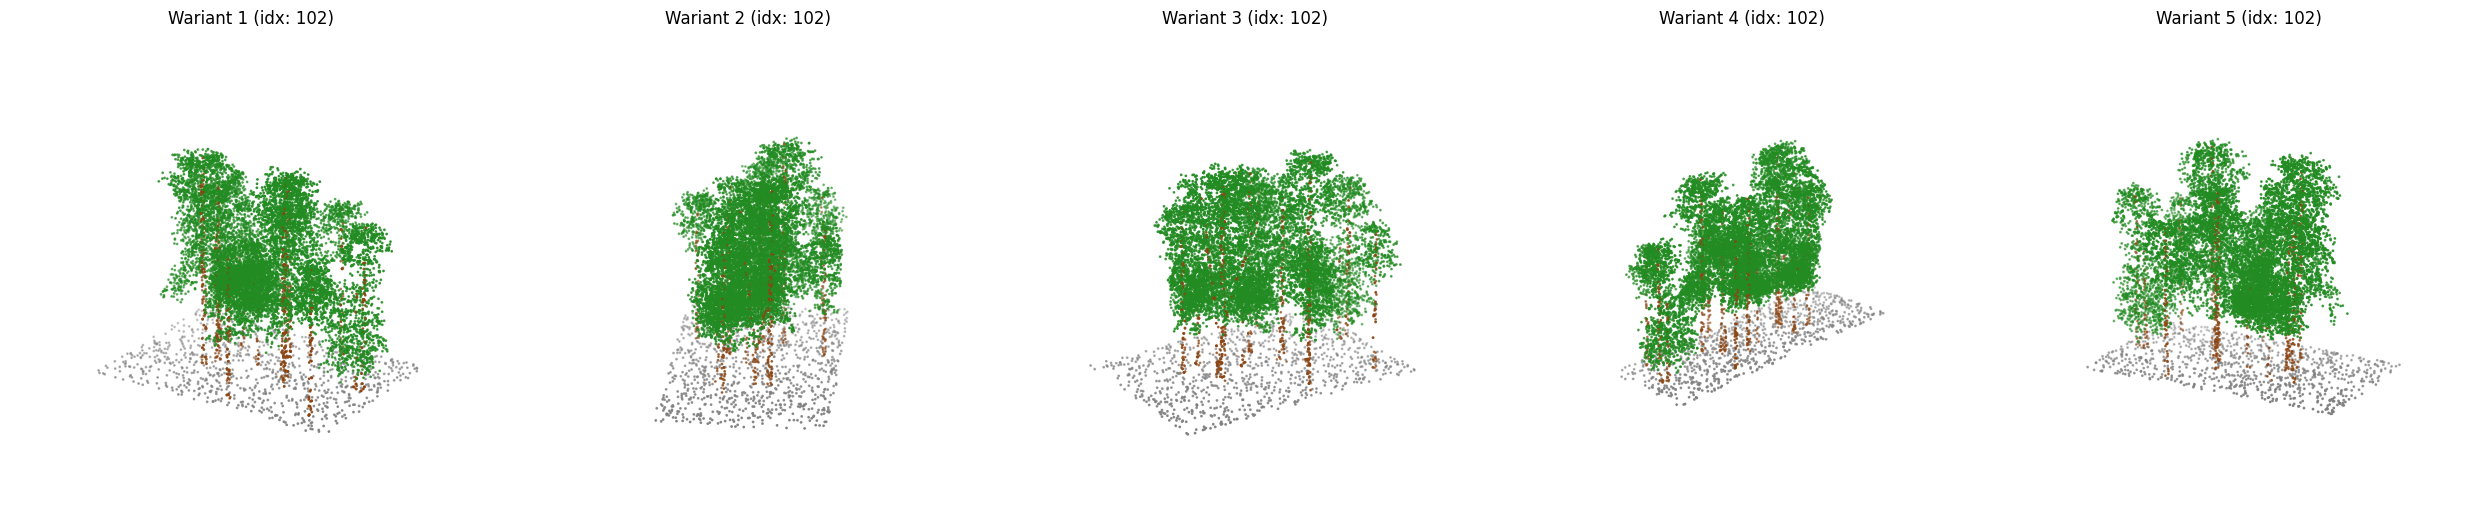

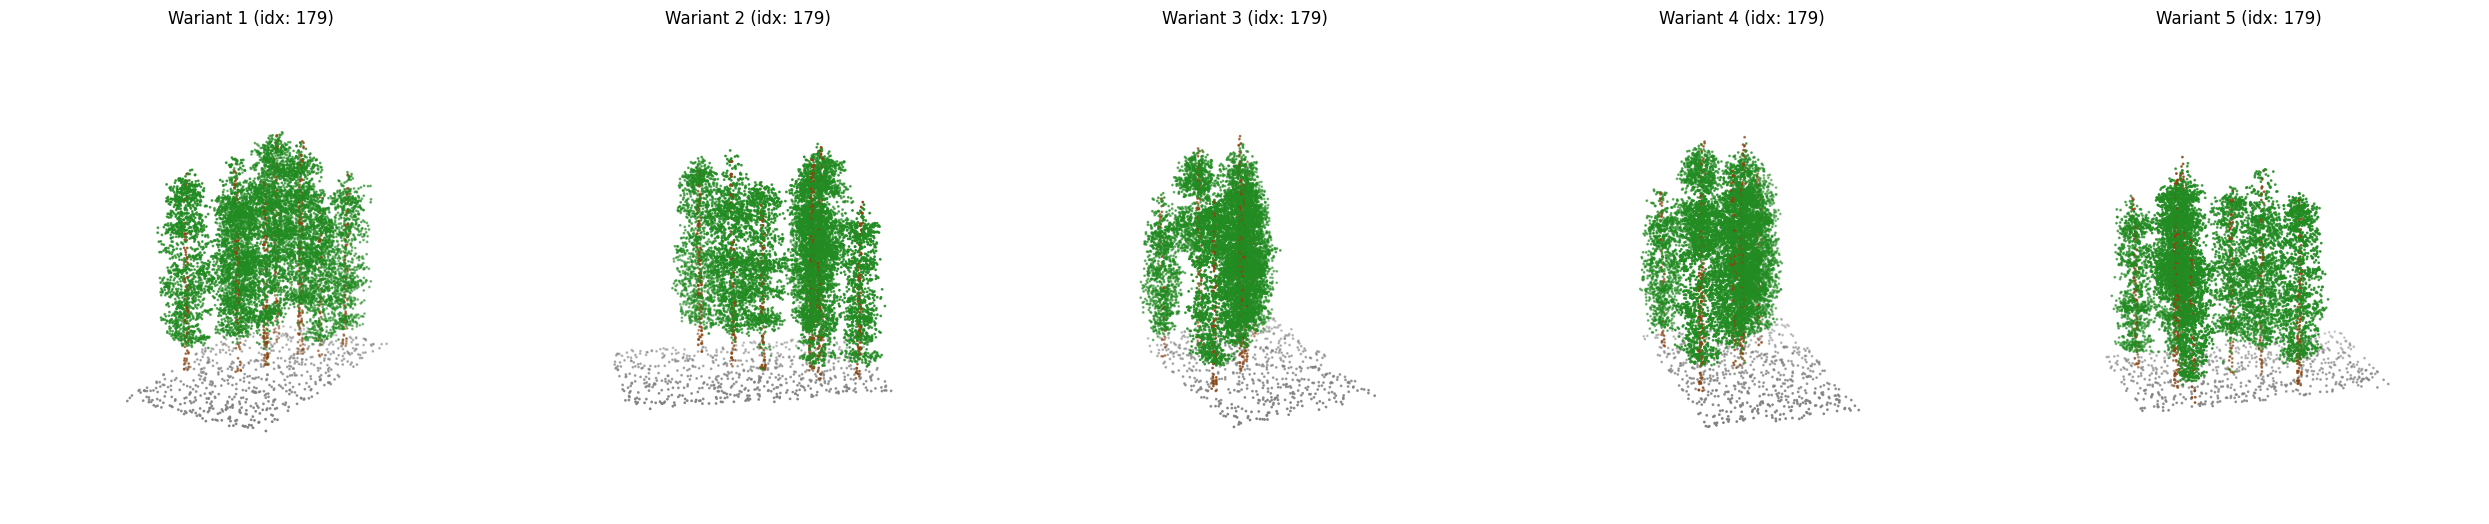

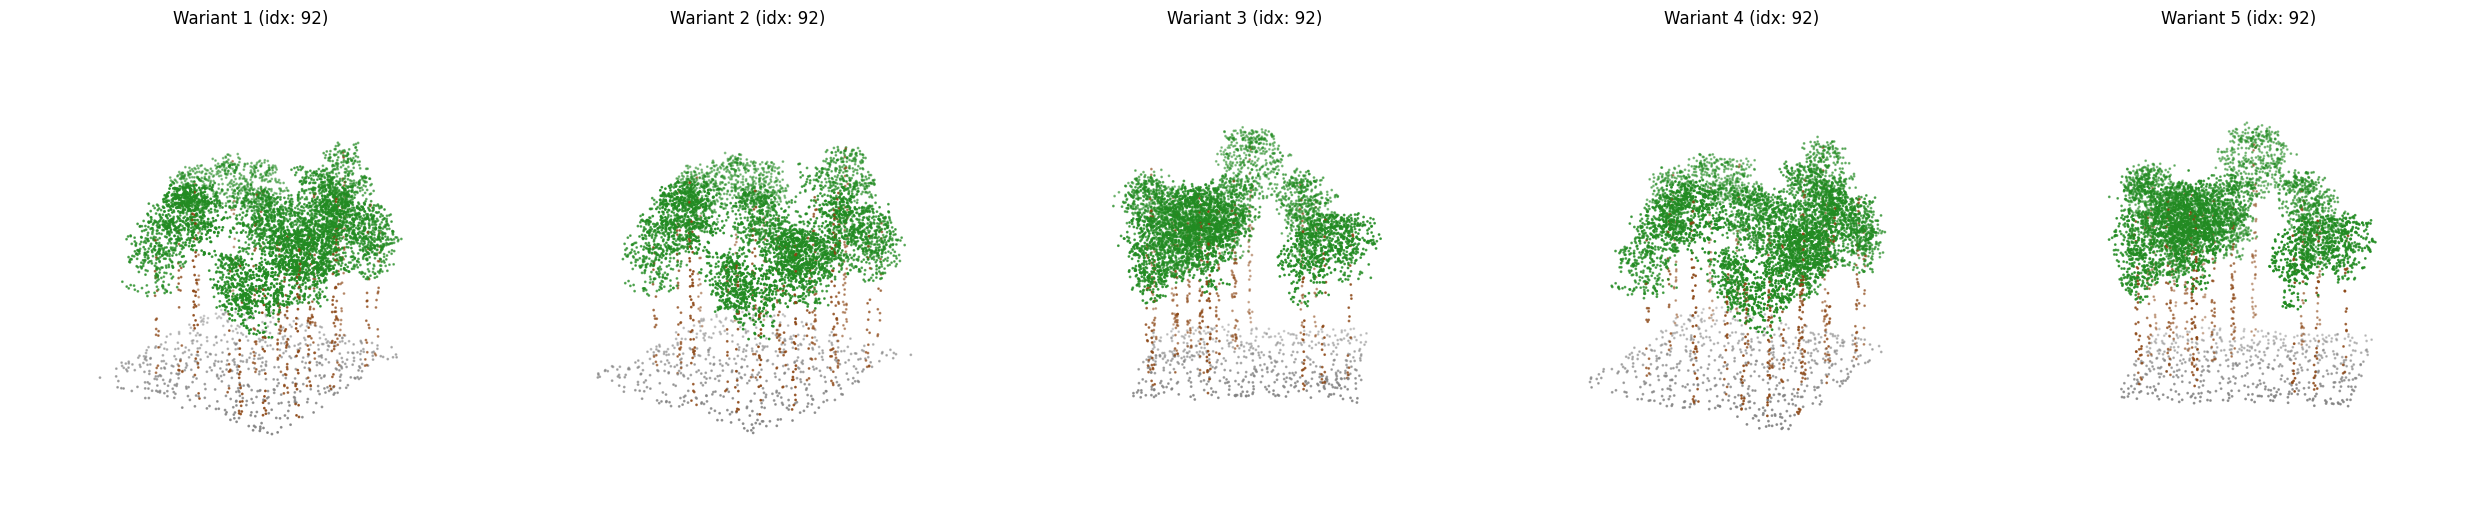

In [ ]:
NUM_VARIANTS = 5 # 3 - 5
for i in range(3):
   visualize_augmentations(train_dataset, sample_idx=np.random.randint(len(train_dataset)), num_variants=NUM_VARIANTS)

## Class Weights

In [ ]:
# Calculate weights based on your training data
class_weights = calculate_class_weights(train_dataset)

for name, idx in CLASS_NAMES.items():
    print(f"Class: {name:<12} | Weight: {class_weights[idx]:.4f}")

Calculating class weights from dataset...


/tmp/ipykernel_2290/2336584706.py:7: UserWarning: It is not recommended to directly access the internal storage format `data` of an 'InMemoryDataset'. The data of the dataset is already cached, so any modifications to `data` will not be reflected when accessing its elements. Clearing the cache now by removing all elements in `dataset._data_list`. If you are absolutely certain what you are doing, access the internal storage via `InMemoryDataset._data` instead to suppress this warning. Alternatively, you can access stacked individual attributes of every graph via `dataset.{attr_name}`.
  all_labels = dataset.data.y.numpy()


Class: background   | Weight: 4.5226
Class: trunk        | Weight: 6.6516
Class: tree_crown   | Weight: 0.3804


## Model Selection

In [ ]:
model_name = MODEL_CONFIG["name"]
model_params = MODEL_CONFIG["params"]

print(f"Initializing Model Architecture: {model_name}...")

if model_name == "PointNetPP":
    model = PointNetPPModel(**model_params).to(device)
elif model_name == "PointNext":
    model = PointNextModel(**model_params).to(device)
else:
    raise ValueError(f"Model architecture '{model_name}' is not recognized.")

Initializing Model Architecture: PointNext...


In [ ]:
# Check of the model
print(f"{model_name} initialized successfully on {device}.")
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {n_params:,}")

PointNext initialized successfully on cuda.
Total trainable parameters: 8,053,347


## Loss Function

In [ ]:
criterion_name = CRITERION_CONFIG["name"]
criterion_params = CRITERION_CONFIG["params"]

print(f"Initializing Loss Function: {criterion_name}...")

# Check if using our custom Hybrid loss or a standard PyTorch loss
if criterion_name == "DiceFocalLoss":
    criterion = DiceFocalLoss(weight=class_weights, **criterion_params).to(device)
elif criterion_name == "FocalLoss":
    criterion = FocalLoss(weight=class_weights, **criterion_params).to(device)
else:
    # Standard PyTorch loss fallback (e.g. CrossEntropyLoss)
    criterion_class = getattr(torch.nn, criterion_name)
    criterion = criterion_class(weight=class_weights, **criterion_params).to(device)

print(f"Loss initialized successfully with class weights.")

Initializing Loss Function: DiceFocalLoss...
Loss initialized successfully with class weights.


## Optimizer

In [ ]:
# 1. Get the class from torch.optim dynamically
optimizer_class = getattr(torch.optim, OPTIMIZER_CONFIG["name"])

# 2. Initialize with model parameters and unpacked hyperparams
optimizer = optimizer_class(
    model.parameters(),
    **OPTIMIZER_CONFIG["params"]
)

print(f"Optimizer: {OPTIMIZER_CONFIG['name']} initialized with params: {OPTIMIZER_CONFIG['params']}")

Optimizer: AdamW initialized with params: {'lr': 0.0001, 'weight_decay': 0.0001}


## Scheduler

In [ ]:
scheduler = get_scheduler(
    optimizer=optimizer,
    scheduler_config=SCHEDULER_CONFIG,
    warmup_epochs=WARMUP_EPOCHS
)

Created Sequential Scheduler: Warmup (5 ep) -> CosineAnnealingLR


## Logger

In [ ]:
# 1. Invert CLASS_NAMES to get names from IDs for the logger
# This allows the logger to label charts as 'trunk' instead of 'class_1'
CLASS_NAMES_INV = {v: k for k, v in CLASS_NAMES.items()}

# 2. Prepare the master configuration dictionary for the logger
# We use the 'globals()' trick to capture all uppercase constants automatically
full_logger_config = {
    "LOGGER": LOGGER,
    "EXP_NAME": EXP_NAME,
    "LOG_DIR": LOG_DIR,
    "OUTPUT_DIR": OUTPUT_DIR,
    # This dictionary comprehension grabs all global constants (uppercase names)
    **{k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, list, dict))}
}

# --- ADDED: Handle authentication/session setup before creating the logger ---
setup_logging_session(full_logger_config)

# 3. Create the master logger object
logger = ForestLogger(
    config=full_logger_config,
    class_names_inv=CLASS_NAMES_INV
)

print(f"Logger initialized as: {LOGGER.upper()}")
if LOGGER.lower() == "tensorboard":
    print(f"Local log path: {os.path.join(LOG_DIR, EXP_NAME)}")

Weights & Biases: Checking authentication...


/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: slowik-lukasz1988 (lukslow) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


WandB: Authentication successful.


WandB session initialized: PointNext_Forest_V1
Logger initialized as: WANDB


## Training

In [ ]:
# ==========================================================
# METRICS TRACKER INITIALIZATION
# ==========================================================
# This object must be created before the loop to be used in validate()
metrics_collection = MetricCollection({
    "iou": MulticlassJaccardIndex(num_classes=len(CLASS_NAMES), average=None),
    "f1": MulticlassF1Score(num_classes=len(CLASS_NAMES), average=None),
    "precision": MulticlassPrecision(num_classes=len(CLASS_NAMES), average=None),
    "recall": MulticlassRecall(num_classes=len(CLASS_NAMES), average=None)
}).to(device)

print(f"Metrics collection initialized for {len(CLASS_NAMES)} classes.")

Metrics collection initialized for 3 classes.


In [ ]:
# ==========================================================
# MAIN EXECUTION RUNNER (Optimized Console Output)
# ==========================================================

# 1. Setup metadata and fixed indices for visual monitoring
CLASS_NAMES_INV = {v: k for k, v in CLASS_NAMES.items()}
best_metric_val = 0.0
start_epoch = 0

# Select random but fixed indices for visualization consistency
indices_to_vis = np.random.choice(len(val_dataset), NUM_VIS, replace=False).tolist()

# 2. Resume logic
if RESUME:
    start_epoch, best_metric_val = load_checkpoint(PATH_TO_CKPT, model, optimizer, scheduler)
    start_epoch += 1

print(f"Starting Experiment: {EXP_NAME}")
print(f"Tracking: {PRIMARY_METRIC} | Monitoring: {indices_to_vis}")

for epoch in range(start_epoch, NUM_EPOCHS):

    # --- A. TRAINING & VALIDATION ---
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device, metrics_collection)

    # --- B. COMPUTE METRICS ---
    computed = metrics_collection.compute()
    mIoU = computed["iou"].mean().item()

    # --- C. LOGGING PACKAGE ASSEMBLY (FULL DATA for WandB/TB) ---
    logs = {
        "train/loss": train_loss,
        "train/accuracy": train_acc,
        "val/loss": val_loss,
        "val/accuracy": val_acc,
        "val/mIoU": mIoU,
        "val/mF1": computed["f1"].mean().item(),
        "charts/learning_rate": optimizer.param_groups[0]['lr']
    }
    # Add all per-class details to backends only
    for class_name, class_id in CLASS_NAMES.items():
        logs[f"val_class_iou/{class_name}"] = computed["iou"][class_id].item()

    # --- D. EXECUTE LOGGING (WandB / TensorBoard) ---
    logger.log_metrics(logs, step=epoch)

    # --- E. VISUAL PROGRESS LOGGING ---
    if epoch % VIS_FREQ == 0:
        fig = generate_prediction_grid(
            val_dataset, model, device, SEMANTIC_COLOR_MAP, indices=indices_to_vis
        )
        logger.log_figure("val/visual_comparisons", fig, step=epoch, save_dir=VIS_DIR)
        plt.close(fig)

    # --- F. COMPACT CONSOLE OUTPUT ---
    # Only general info on one line for better scrollability
    summary_msg = (f"Epoch {epoch:03d} | "
                   f"Loss (T/V): {train_loss:.4f}/{val_loss:.4f} | "
                   f"mIoU: {mIoU:.4f} | "
                   f"Acc (V): {val_acc:.4f}")

    # --- G. CHECKPOINTING LOGIC ---
    current_val = logs.get(PRIMARY_METRIC, 0.0)
    is_best = current_val > best_metric_val

    if is_best:
        best_metric_val = current_val
        summary_msg += f" | BEST ({PRIMARY_METRIC.split('/')[-1]})"

    print(summary_msg)

    # Save state
    save_checkpoint({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'miou': mIoU,
        'metrics': logs
    }, is_best, CHECKPOINT_DIR, EXP_NAME)

    # Update learning rate
    scheduler.step()

# Cleanup
logger.finish()
print("Training completed.")

Starting Experiment: PointNext_Forest_V1
Tracking: val/mIoU | Monitoring: [26, 13, 24]


Training:   0%|          | 0/27 [00:00<?, ?it/s]

Validation:   0%|          | 0/5 [00:00<?, ?it/s]

Epoch 000 | Loss (T/V): 0.7124/0.8533 | mIoU: 0.2642 | Acc (V): 0.7850 | BEST (mIoU)
Best model saved with mIoU: 0.2642


Training:   0%|          | 0/27 [00:00<?, ?it/s]

Validation:   0%|          | 0/5 [00:00<?, ?it/s]

... (32 outputs left out)

Validation:   0%|          | 0/5 [00:00<?, ?it/s]

Epoch 012 | Loss (T/V): 0.3135/0.6383 | mIoU: 0.7070 | Acc (V): 0.8877


Training:   0%|          | 0/27 [00:00<?, ?it/s]

KeyboardInterrupt: 

## Final Evaluation & Analysis

/tmp/ipykernel_2290/2020796683.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(os.path.join(CHECKPOINT_DIR, f"{EXP_NAME}_best.pth"))


Loaded best model from epoch 6 (mIoU: 0.7266)



CLASSIFICATION REPORT:
              precision    recall  f1-score   support

  background     0.9805    0.9607    0.9705     48732
       trunk     0.7255    0.4011    0.5166     77525
  tree_crown     0.9059    0.9762    0.9397    459310

    accuracy                         0.8988    585567
   macro avg     0.8706    0.7793    0.8090    585567
weighted avg     0.8882    0.8988    0.8863    585567



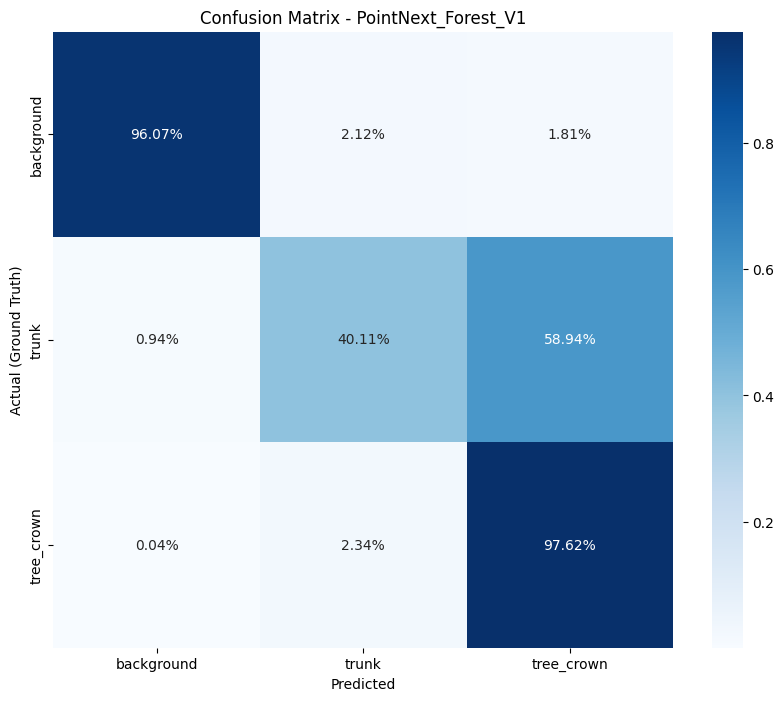

In [ ]:
# 1. Load the best weights
checkpoint = torch.load(os.path.join(CHECKPOINT_DIR, f"{EXP_NAME}_best.pth"))
model.load_state_dict(checkpoint['model_state_dict'])
print(f"Loaded best model from epoch {checkpoint['epoch']} (mIoU: {checkpoint['miou']:.4f})")

# 2. Get predictions for the whole validation set
y_true, y_pred = get_all_predictions(model, val_loader, device)

# 3. Generate Classification Report
# target_names takes names from your CLASS_NAMES_INV
target_names = [CLASS_NAMES_INV[i] for i in range(len(CLASS_NAMES))]
print("\nCLASSIFICATION REPORT:")
print(classification_report(y_true, y_pred, target_names=target_names, digits=4))

# 4. Generate Confusion Matrix Visualization
cm = confusion_matrix(y_true, y_pred, normalize='true') # normalized by row (GT)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='.2%', xticklabels=target_names, yticklabels=target_names, cmap='Blues')
plt.title(f"Confusion Matrix - {EXP_NAME}")
plt.xlabel("Predicted")
plt.ylabel("Actual (Ground Truth)")

# Save matrix to your visualization folder
plt.savefig(os.path.join(VIS_DIR, "final_confusion_matrix.png"), bbox_inches='tight')
plt.show()

## Prediction Visualisation

Generating final visualizations for samples: [15, 12, 4, 23]


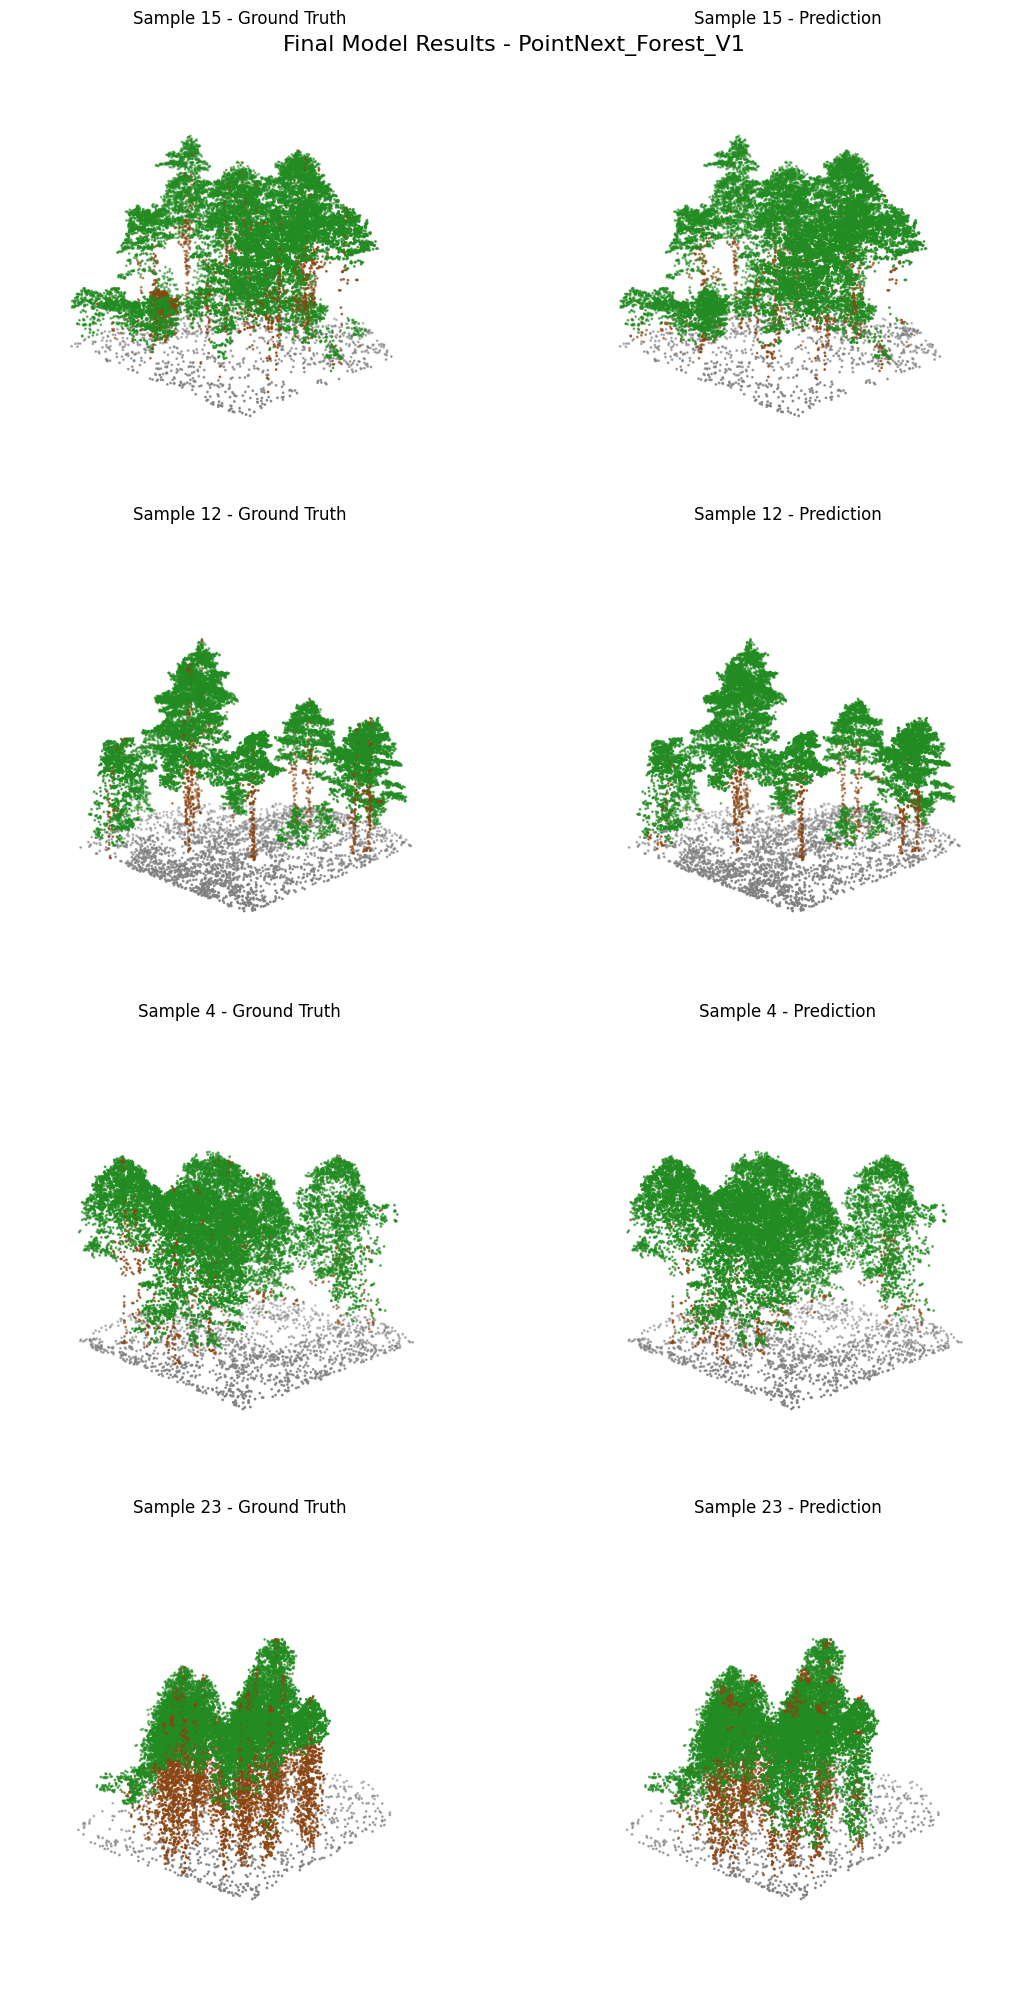

In [ ]:
num_final_vis = 4
final_indices = np.random.choice(len(val_dataset), num_final_vis, replace=False).tolist()

print(f"Generating final visualizations for samples: {final_indices}")

fig_final = generate_prediction_grid(
    val_dataset,
    model,
    device,
    SEMANTIC_COLOR_MAP,
    indices=final_indices
)

plt.suptitle(f"Final Model Results - {EXP_NAME}", fontsize=16)
plt.show()

## Inference And Export

In [ ]:
run_inference_and_export(
    model=model,
    dataloader=val_loader,
    device=device,
    output_dir=PRED_DIR
)